In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/Superstore.csv", encoding='latin1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
df.shape

(9994, 21)

In [4]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Region"].unique()

array(['South', 'West', 'Central', 'East'], dtype=object)

In [9]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [10]:
df["Sales"] = df["Sales"].fillna(df["Sales"].median())

In [11]:
df["Region"] = df["Region"].fillna(df["Region"].mode()[0])

In [12]:
df["Customer Name"] = df["Customer Name"].fillna("Unknown")

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df = df.drop_duplicates()

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df["Region"] = df["Region"].str.strip().str.title()

In [17]:
df["Category"] = df["Category"].str.strip().str.title()

In [18]:
df["Customer Name"] = df["Customer Name"].str.strip().str.title()

In [19]:
df.dtypes

,0
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [20]:
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

In [21]:
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Profit"] = pd.to_numeric(df["Profit"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

In [22]:
df[df["Sales"] < 0]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [23]:
df[df["Quantity"] <= 0]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [24]:
df[(df["Discount"] < 0) | (df["Discount"] > 1)]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [25]:
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Sales"] < lower) | (df["Sales"] > upper)]

print("Number of outliers:", len(outliers))

Number of outliers: 1167


In [26]:
df.to_csv(
    "cleaned_sales_data.csv",
    index=False
)

In [27]:
total_sales = df["Sales"].sum()
print(total_sales)

2297200.8603000003


In [28]:
total_profit = df["Profit"].sum()
print(total_profit)

286397.0217


In [29]:
average_sales = df["Sales"].mean()
print(average_sales)

229.85800083049833


In [30]:
total_orders = df["Order ID"].nunique()
print(total_orders)

5009


In [31]:
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales)

Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


In [32]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


In [33]:
category_profit = df.groupby("Category")["Profit"].sum()

print(category_profit)

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


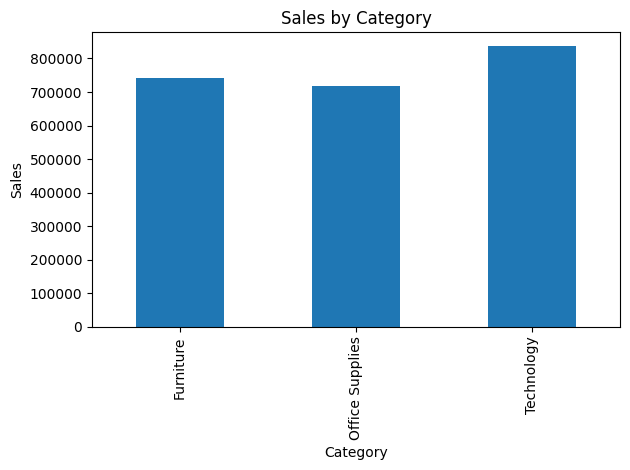

In [34]:
category_sales.plot(kind="bar")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

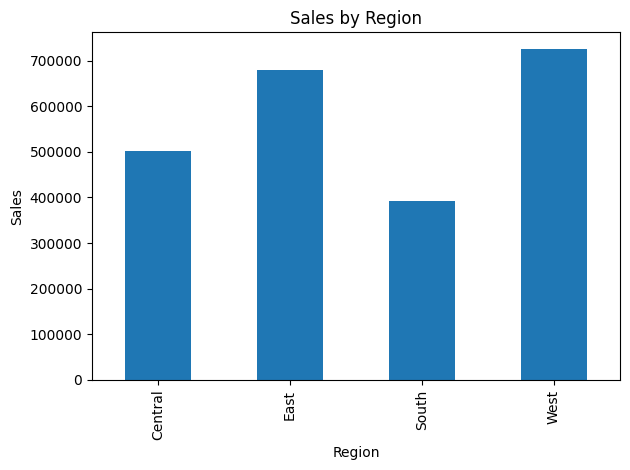

In [35]:
region_sales.plot(kind="bar")

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

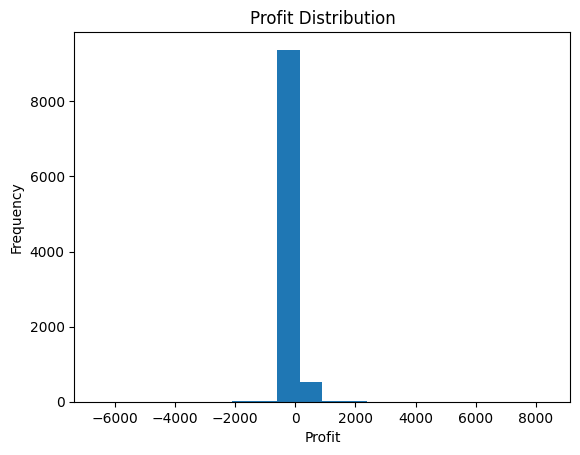

In [36]:
plt.hist(df["Profit"], bins=20)

plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

In [37]:
with pd.ExcelWriter(
    "sales_report.xlsx",
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned Data",
        index=False
    )

    region_sales.to_excel(
        writer,
        sheet_name="Sales by Region"
    )

    category_sales.to_excel(
        writer,
        sheet_name="Sales by Category"
    )

In [39]:
def load_data():
    pass

def check_data_quality():
    pass

def clean_missing_values():
    pass

def remove_duplicates():
    pass

def standardize_data():
    pass

def validate_data():
    pass

def generate_summary():
    pass

def generate_visualizations():
    pass

def generate_report():
    pass

In [40]:
def main():

    # Load
    # Clean
    # Validate
    # Analyze
    # Visualize
    # Report

    print("Automation completed successfully!")

In [41]:
if __name__ == "__main__":
    main()

Automation completed successfully!


In [42]:
import pandas as pd

cleaned_df = pd.read_csv("/content/cleaned_sales_data.csv")

print("Cleaned Dataset Shape:", cleaned_df.shape)

print("\nMissing Values:")
print(cleaned_df.isnull().sum())

print("\nDuplicate Rows:")
print(cleaned_df.duplicated().sum())

print("\nFirst 5 Rows:")
display(cleaned_df.head())

Cleaned Dataset Shape: (9994, 21)

Missing Values:
Row ID              0
Order ID            0
Order Date       5952
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Postal Code         0
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit              0
dtype: int64

Duplicate Rows:
0

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [43]:
print("===== DATASET SUMMARY =====")

print("Total Records:", len(cleaned_df))

print("Total Sales:", cleaned_df["Sales"].sum())

print("Average Sales:", cleaned_df["Sales"].mean())

print("Total Profit:", cleaned_df["Profit"].sum())

print("Average Profit:", cleaned_df["Profit"].mean())

===== DATASET SUMMARY =====
Total Records: 9994
Total Sales: 2297200.8603000003
Average Sales: 229.85800083049833
Total Profit: 286397.0217
Average Profit: 28.65689630778467


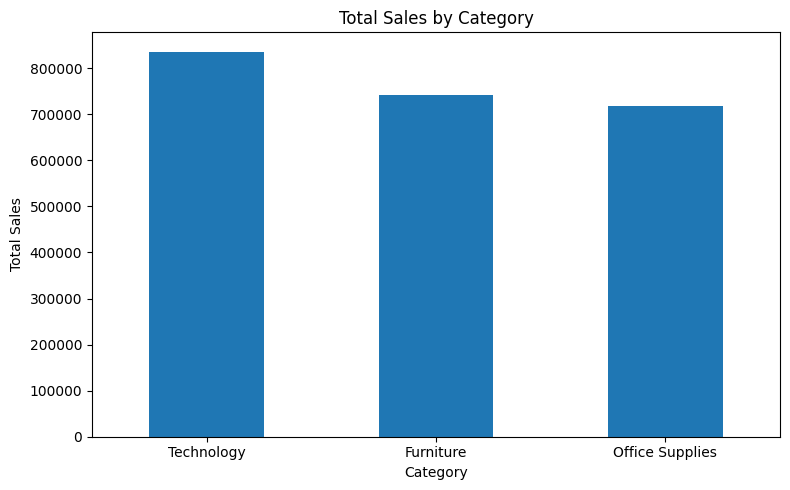

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

category_sales = cleaned_df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("sales_by_category.png")
plt.show()

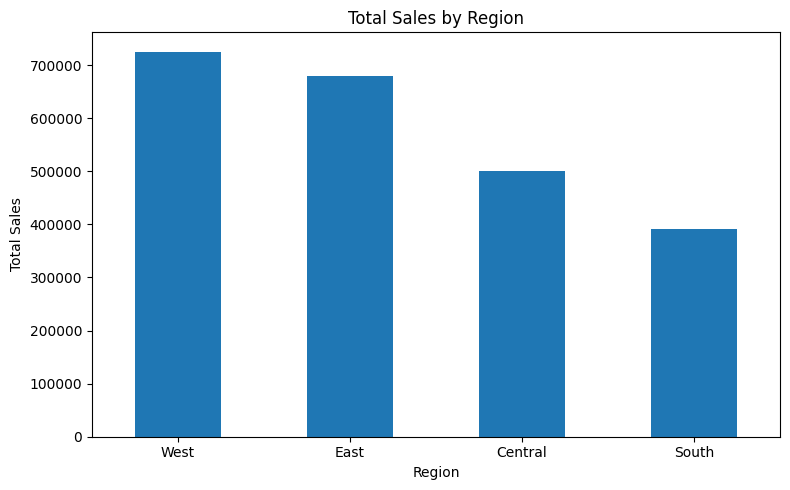

In [45]:
region_sales = cleaned_df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
region_sales.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("sales_by_region.png")
plt.show()

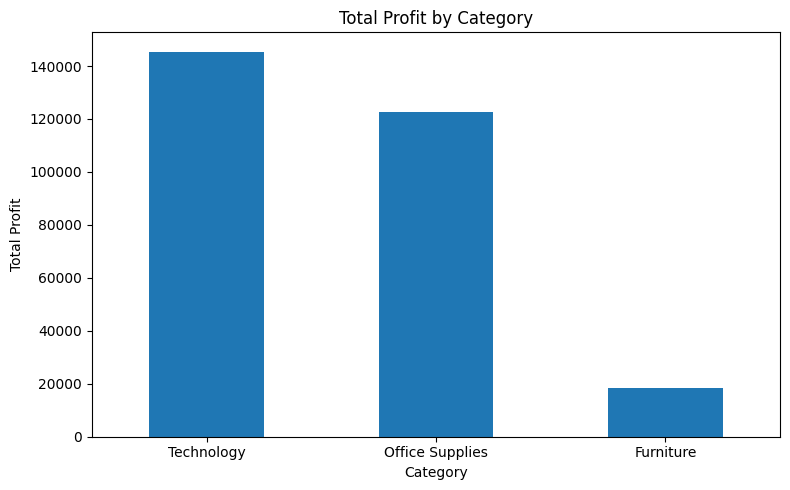

In [46]:
category_profit = cleaned_df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(8,5))
category_profit.plot(kind="bar")

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("profit_by_category.png")
plt.show()

In [47]:
print(cleaned_df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


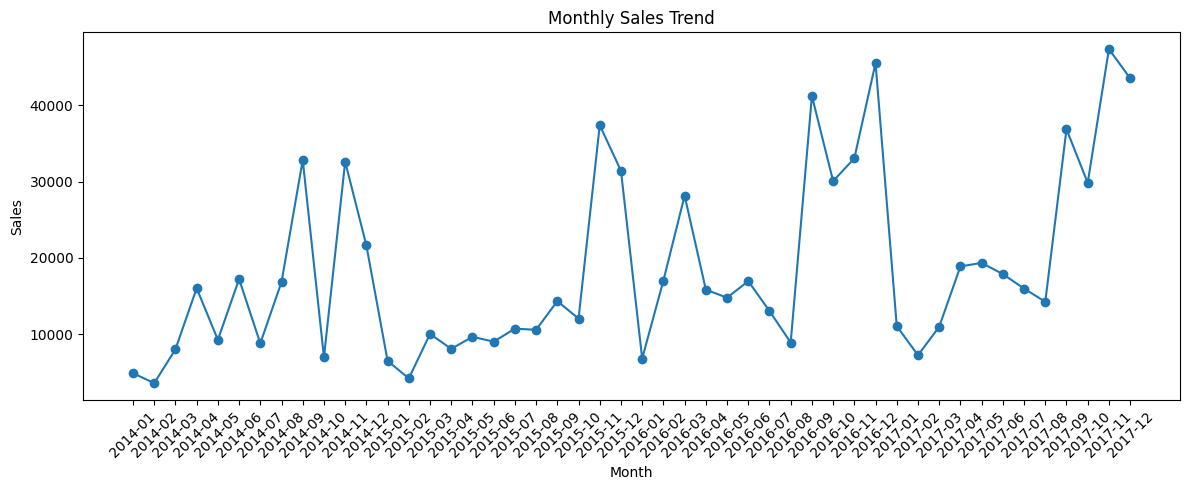

In [48]:
cleaned_df["Order Date"] = pd.to_datetime(
    cleaned_df["Order Date"],
    errors="coerce"
)

monthly_sales = (
    cleaned_df
    .groupby(cleaned_df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("monthly_sales_trend.png")
plt.show()

In [55]:
raw_df = pd.read_csv("/content/Superstore.csv", encoding='latin1')

quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Missing Values",
        "Duplicate Rows"
    ],

    "Before Cleaning": [
        len(raw_df),
        raw_df.isnull().sum().sum(),
        raw_df.duplicated().sum()
    ],

    "After Cleaning": [
        len(cleaned_df),
        cleaned_df.isnull().sum().sum(),
        cleaned_df.duplicated().sum()
    ]
})

display(quality_report)

,Metric,Before Cleaning,After Cleaning
0,Total Records,9994,9994
1,Missing Values,0,5952
2,Duplicate Rows,0,0


In [52]:
with pd.ExcelWriter(
    "sales_report.xlsx",
    engine="openpyxl"
) as writer:

    cleaned_df.to_excel(
        writer,
        sheet_name="Cleaned Data",
        index=False
    )

    quality_report.to_excel(
        writer,
        sheet_name="Data Quality",
        index=False
    )

    category_sales.to_frame("Total Sales").to_excel(
        writer,
        sheet_name="Sales by Category"
    )

    region_sales.to_frame("Total Sales").to_excel(
        writer,
        sheet_name="Sales by Region"
    )

    category_profit.to_frame("Total Profit").to_excel(
        writer,
        sheet_name="Profit by Category"
    )

print("Excel report generated successfully!")

Excel report generated successfully!


In [53]:
# ==============================
# EXECUTIVE SUMMARY
# ==============================

total_records = len(cleaned_df)
total_sales = cleaned_df["Sales"].sum()
total_profit = cleaned_df["Profit"].sum()
average_sales = cleaned_df["Sales"].mean()
average_profit = cleaned_df["Profit"].mean()
total_orders = cleaned_df["Order ID"].nunique()

print("=" * 50)
print("        DATA CLEANING & REPORTING SUMMARY")
print("=" * 50)

print(f"Total Records       : {total_records:,}")
print(f"Total Orders        : {total_orders:,}")
print(f"Total Sales         : {total_sales:,.2f}")
print(f"Total Profit        : {total_profit:,.2f}")
print(f"Average Sales       : {average_sales:,.2f}")
print(f"Average Profit      : {average_profit:,.2f}")

print("=" * 50)

        DATA CLEANING & REPORTING SUMMARY
Total Records       : 9,994
Total Orders        : 5,009
Total Sales         : 2,297,200.86
Total Profit        : 286,397.02
Average Sales       : 229.86
Average Profit      : 28.66


In [56]:
# ==============================
# DATA QUALITY COMPARISON
# ==============================

raw_df = pd.read_csv("Superstore.csv", encoding='latin1')

quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Missing Values",
        "Duplicate Rows"
    ],

    "Before Cleaning": [
        len(raw_df),
        raw_df.isnull().sum().sum(),
        raw_df.duplicated().sum()
    ],

    "After Cleaning": [
        len(cleaned_df),
        cleaned_df.isnull().sum().sum(),
        cleaned_df.duplicated().sum()
    ]
})

display(quality_report)

,Metric,Before Cleaning,After Cleaning
0,Total Records,9994,9994
1,Missing Values,0,5952
2,Duplicate Rows,0,0


In [57]:
with pd.ExcelWriter(
    "sales_report.xlsx",
    engine="openpyxl"
) as writer:

    # Cleaned data
    cleaned_df.to_excel(
        writer,
        sheet_name="Cleaned Data",
        index=False
    )

    # Data quality
    quality_report.to_excel(
        writer,
        sheet_name="Data Quality",
        index=False
    )

    # Sales by category
    category_sales.to_frame(
        "Total Sales"
    ).to_excel(
        writer,
        sheet_name="Sales by Category"
    )

    # Sales by region
    region_sales.to_frame(
        "Total Sales"
    ).to_excel(
        writer,
        sheet_name="Sales by Region"
    )

    # Profit by category
    category_profit.to_frame(
        "Total Profit"
    ).to_excel(
        writer,
        sheet_name="Profit by Category"
    )

print("Final Excel report created successfully!")

Final Excel report created successfully!


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


def automate_data_cleaning(input_file, output_folder="final_output"):

    # --------------------------------
    # 1. Create output folder
    # --------------------------------
    os.makedirs(output_folder, exist_ok=True)
    os.makedirs(os.path.join(output_folder, "charts"), exist_ok=True)

    # --------------------------------
    # 2. Load raw data
    # --------------------------------
    raw_df = pd.read_csv(input_file, encoding="latin1")

    print("Raw dataset loaded successfully!")
    print("Original records:", len(raw_df))

    # Keep a copy for comparison
    df = raw_df.copy()

    # --------------------------------
    # 3. Data quality BEFORE cleaning
    # --------------------------------
    missing_before = df.isnull().sum().sum()
    duplicates_before = df.duplicated().sum()

    # --------------------------------
    # 4. Remove duplicate records
    # --------------------------------
    df = df.drop_duplicates()

    # --------------------------------
    # 5. Handle missing values
    # --------------------------------
    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns

    for column in numeric_columns:
        df[column] = df[column].fillna(
            df[column].median()
        )

    categorical_columns = df.select_dtypes(
        include="object"
    ).columns

    for column in categorical_columns:
        df[column] = df[column].fillna("Unknown")

    # --------------------------------
    # 6. Standardize text data
    # --------------------------------
    for column in categorical_columns:
        df[column] = df[column].astype(str).str.strip()

    # --------------------------------
    # 7. Convert date columns
    # --------------------------------
    if "Order Date" in df.columns:
        df["Order Date"] = pd.to_datetime(
            df["Order Date"],
            errors="coerce"
        )

    # --------------------------------
    # 8. Data quality AFTER cleaning
    # --------------------------------
    missing_after = df.isnull().sum().sum()
    duplicates_after = df.duplicated().sum()

    # --------------------------------
    # 9. Save cleaned dataset
    # --------------------------------
    cleaned_file = os.path.join(
        output_folder,
        "cleaned_sales_data.csv"
    )

    df.to_csv(
        cleaned_file,
        index=False
    )

    # --------------------------------
    # 10. Calculate KPIs
    # --------------------------------
    total_records = len(df)

    total_sales = (
        df["Sales"].sum()
        if "Sales" in df.columns
        else 0
    )

    total_profit = (
        df["Profit"].sum()
        if "Profit" in df.columns
        else 0
    )

    average_sales = (
        df["Sales"].mean()
        if "Sales" in df.columns
        else 0
    )

    average_profit = (
        df["Profit"].mean()
        if "Profit" in df.columns
        else 0
    )

    total_orders = (
        df["Order ID"].nunique()
        if "Order ID" in df.columns
        else total_records
    )

    # --------------------------------
    # 11. Create summary
    # --------------------------------
    summary = pd.DataFrame({
        "Metric": [
            "Total Records",
            "Total Orders",
            "Total Sales",
            "Total Profit",
            "Average Sales",
            "Average Profit"
        ],

        "Value": [
            total_records,
            total_orders,
            total_sales,
            total_profit,
            average_sales,
            average_profit
        ]
    })

    # --------------------------------
    # 12. Data quality report
    # --------------------------------
    quality_report = pd.DataFrame({
        "Metric": [
            "Total Records",
            "Missing Values",
            "Duplicate Rows"
        ],

        "Before Cleaning": [
            len(raw_df),
            missing_before,
            duplicates_before
        ],

        "After Cleaning": [
            len(df),
            missing_after,
            duplicates_after
        ]
    })

    # --------------------------------
    # 13. Sales by Category
    # --------------------------------
    if "Category" in df.columns and "Sales" in df.columns:

        category_sales = (
            df.groupby("Category")["Sales"]
            .sum()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(8, 5))

        category_sales.plot(kind="bar")

        plt.title("Total Sales by Category")
        plt.xlabel("Category")
        plt.ylabel("Sales")

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                output_folder,
                "charts",
                "sales_by_category.png"
            )
        )

        plt.show()

    # --------------------------------
    # 14. Sales by Region
    # --------------------------------
    if "Region" in df.columns and "Sales" in df.columns:

        region_sales = (
            df.groupby("Region")["Sales"]
            .sum()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(8, 5))

        region_sales.plot(kind="bar")

        plt.title("Total Sales by Region")
        plt.xlabel("Region")
        plt.ylabel("Sales")

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                output_folder,
                "charts",
                "sales_by_region.png"
            )
        )

        plt.show()

    # --------------------------------
    # 15. Profit by Category
    # --------------------------------
    if "Category" in df.columns and "Profit" in df.columns:

        category_profit = (
            df.groupby("Category")["Profit"]
            .sum()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(8, 5))

        category_profit.plot(kind="bar")

        plt.title("Total Profit by Category")
        plt.xlabel("Category")
        plt.ylabel("Profit")

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                output_folder,
                "charts",
                "profit_by_category.png"
            )
        )

        plt.show()

    # --------------------------------
    # 16. Monthly Sales Trend
    # --------------------------------
    if "Order Date" in df.columns and "Sales" in df.columns:

        monthly_sales = (
            df.groupby(
                df["Order Date"].dt.to_period("M")
            )["Sales"]
            .sum()
        )

        plt.figure(figsize=(12, 5))

        plt.plot(
            monthly_sales.index.astype(str),
            monthly_sales.values,
            marker="o"
        )

        plt.title("Monthly Sales Trend")
        plt.xlabel("Month")
        plt.ylabel("Sales")

        plt.xticks(rotation=45)

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                output_folder,
                "charts",
                "monthly_sales_trend.png"
            )
        )

        plt.show()

    # --------------------------------
    # 17. Generate Excel report
    # --------------------------------
    report_file = os.path.join(
        output_folder,
        "sales_report.xlsx"
    )

    with pd.ExcelWriter(
        report_file,
        engine="openpyxl"
    ) as writer:

        summary.to_excel(
            writer,
            sheet_name="Summary",
            index=False
        )

        quality_report.to_excel(
            writer,
            sheet_name="Data Quality",
            index=False
        )

        df.to_excel(
            writer,
            sheet_name="Cleaned Data",
            index=False
        )

        if "Category" in df.columns and "Sales" in df.columns:
            category_sales.to_frame(
                "Total Sales"
            ).to_excel(
                writer,
                sheet_name="Sales by Category"
            )

        if "Region" in df.columns and "Sales" in df.columns:
            region_sales.to_frame(
                "Total Sales"
            ).to_excel(
                writer,
                sheet_name="Sales by Region"
            )

        if "Category" in df.columns and "Profit" in df.columns:
            category_profit.to_frame(
                "Total Profit"
            ).to_excel(
                writer,
                sheet_name="Profit by Category"
            )

    # --------------------------------
    # 18. Final message
    # --------------------------------
    print("\n" + "=" * 60)
    print("DATA CLEANING & REPORTING AUTOMATION COMPLETED")
    print("=" * 60)

    print("Cleaned dataset :", cleaned_file)
    print("Excel report    :", report_file)

    print("\nData Quality:")
    print("Missing values before:", missing_before)
    print("Missing values after :", missing_after)
    print("Duplicates before    :", duplicates_before)
    print("Duplicates after     :", duplicates_after)

    print("\nKPI Summary:")
    print("Total Sales  :", round(total_sales, 2))
    print("Total Profit :", round(total_profit, 2))
    print("Total Orders :", total_orders)

    print("=" * 60)

    return df, summary, quality_report

Raw dataset loaded successfully!
Original records: 9994


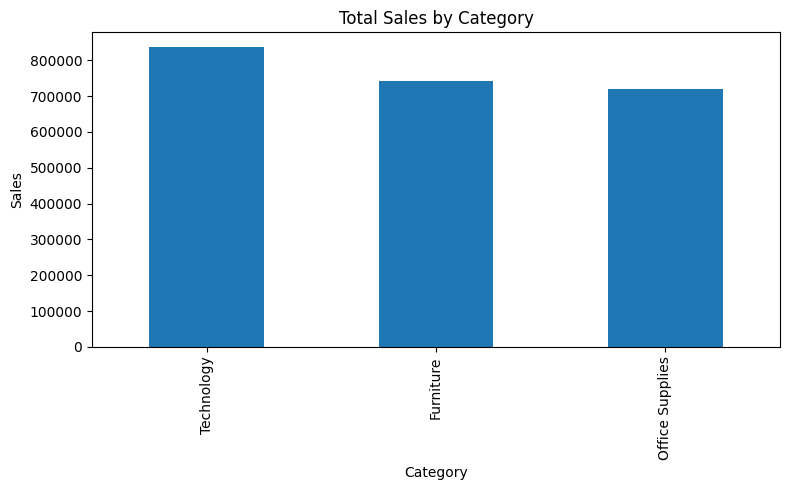

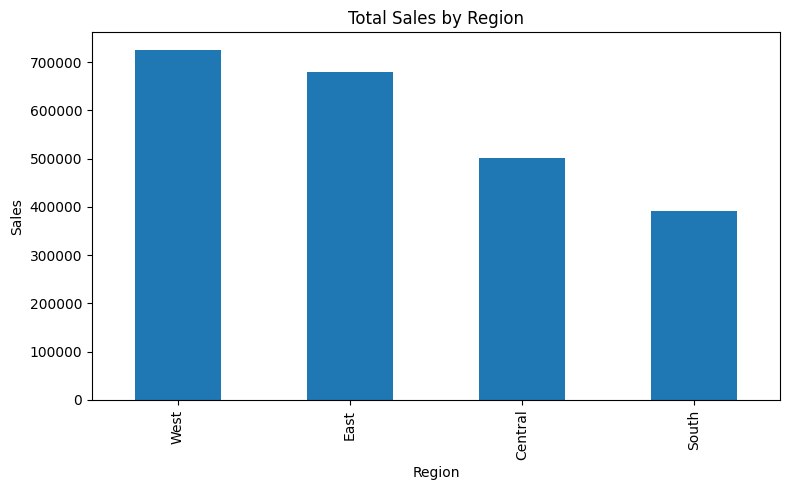

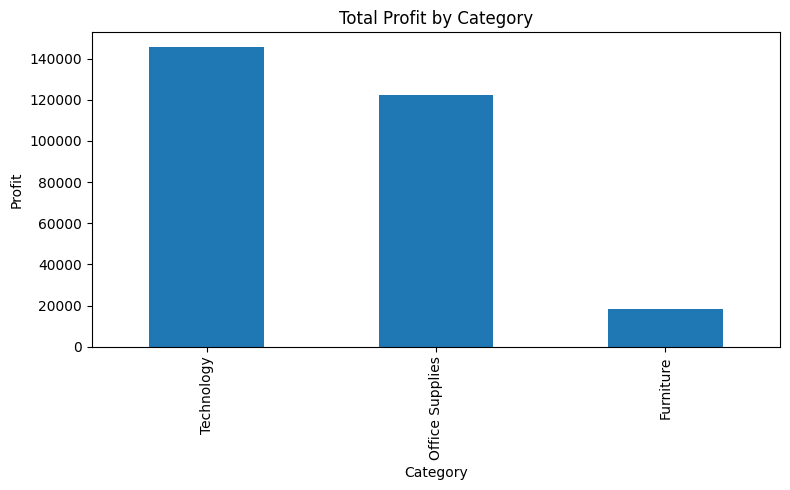

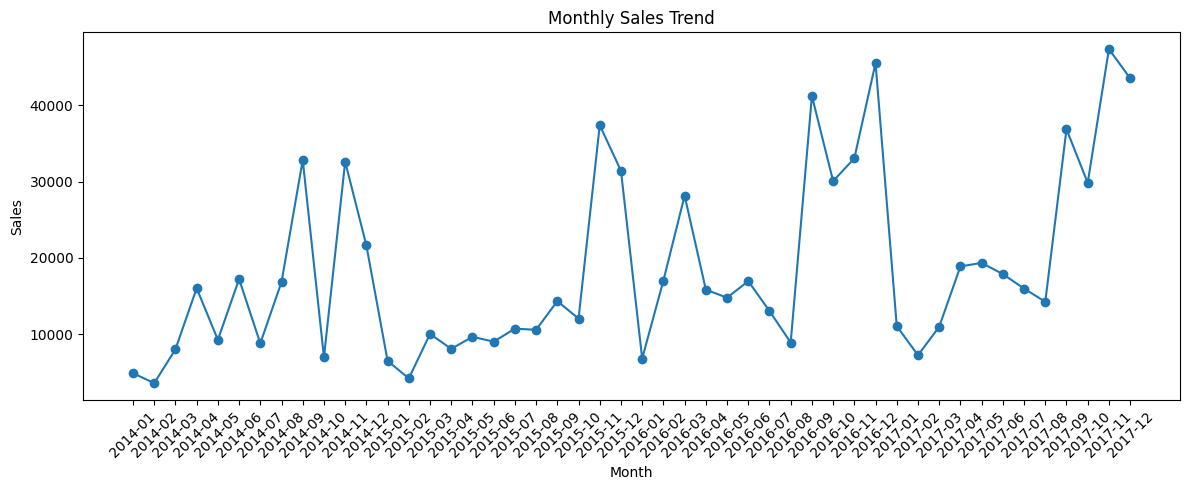


DATA CLEANING & REPORTING AUTOMATION COMPLETED
Cleaned dataset : final_output/cleaned_sales_data.csv
Excel report    : final_output/sales_report.xlsx

Data Quality:
Missing values before: 0
Missing values after : 5952
Duplicates before    : 0
Duplicates after     : 0

KPI Summary:
Total Sales  : 2297200.86
Total Profit : 286397.02
Total Orders : 5009


In [59]:
cleaned_df, summary, quality_report = automate_data_cleaning(
    "Superstore.csv"
)